[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L10/L10_coordinate_search.ipynb)

# Coordinate Search: The First DFO Algorithm
### MECH 559 - Systems Optimization - L10
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

This notebook focuses on Coordinate Search (CS), a foundational derivative-free optimization method based on directional polling.

## Learning objectives

By the end, students should be able to:

1. Implement and run Coordinate Search with step-size updates.
2. Interpret CS trajectories and objective-value reduction under a fixed budget.
3. Explain the role of polling directions and step-size reduction in convergence behavior.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {
    "cs": "#1D5FA8",
    "optimum": "#EDAE49",
}

OMADS 2610, results and logs written to a temporary folder


---
## 1. Test problem

We use a smooth 2D objective from the lecture:

$$
f(x_1, x_2) = (5x_1 - 2)^4 + (5x_1 - 2)^2 x_2^2 + (3x_2 + 1)^2
$$

with minimizer $x^\star = (0.4, -1/3)$ and $f(x^\star)=0$.

We start from $x^0=(2,2)$ and track Coordinate Search under a fixed evaluation budget.

In [ ]:
def f(x):
    x1, x2 = x
    return (5 * x1 - 2) ** 4 + (5 * x1 - 2) ** 2 * x2 ** 2 + (3 * x2 + 1) ** 2


x0 = np.array([2.0, 2.0])
x_star = np.array([0.4, -1.0 / 3.0])

xs = np.linspace(-0.5, 2.5, 300)
ys = np.linspace(-1.0, 2.5, 300)
X, Y = np.meshgrid(xs, ys)
Z = f([X, Y])

print(f"f(x0) = {f(x0):.4f}, f(x*) = {f(x_star):.4e}")

---
## 2. Coordinate Search (CS)

At each iteration, CS polls the coordinate directions

$$
D_{CS} = \{\pm e_1, \pm e_2\}
$$

using trial points $x^k + \Delta^k d$.

- If an improving point is found, accept it and keep $\Delta^k$.
- If no improvement is found, halve the step size.

In [ ]:
def coordinate_search(func, x0, delta0=1.0, budget=120, opportunistic=True):
    D = [np.array([1.0, 0.0]), np.array([0.0, 1.0]), np.array([-1.0, 0.0]), np.array([0.0, -1.0])]
    x = np.array(x0, dtype=float)
    fx = func(x)
    delta = float(delta0)
    n_eval = 0
    history = [{"evals": n_eval, "x": x.copy(), "f": fx, "delta": delta}]

    while n_eval < budget and delta > 1e-10:
        best = None
        for d in D:
            if n_eval >= budget:
                break
            xt = x + delta * d
            ft = func(xt)
            n_eval += 1
            if ft < fx and (best is None or ft < best[1]):
                best = (xt, ft)
                if opportunistic:
                    break
        if best is None:
            delta *= 0.5
        else:
            x, fx = best
        history.append({"evals": n_eval, "x": x.copy(), "f": fx, "delta": delta})
    return x, fx, history

,run,fmin,hmin,xmin,blackbox calls,time [s]
0,poll,2.154162e-03,1.000000e-15,"[0.95362, 0.90956]",1000,1.4
1,search,1.046788e+00,1.000000e-15,"[2.02277, 4.0943]",1000,2.0
2,mads,4.375627e-12,1.000000e-15,"[1.0, 1.0]",499,0.7
3,search (opportunistic),0.000000e+00,1.000000e-15,"[1.0, 1.0]",302,0.7


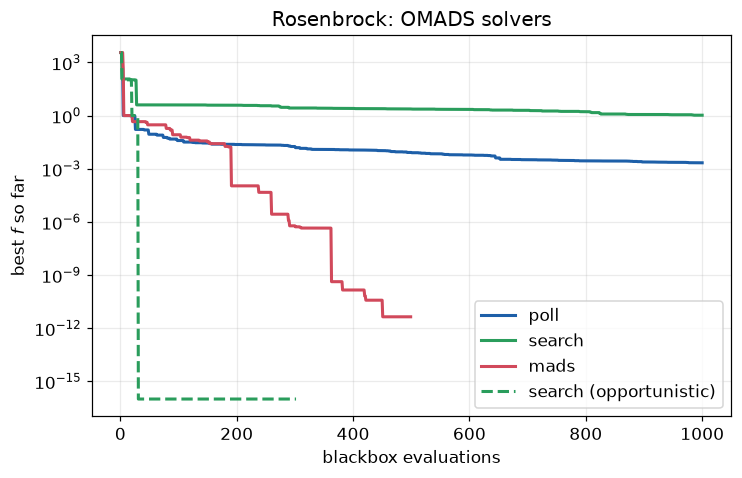

In [ ]:
x_cs, f_cs, H_cs = coordinate_search(f, x0, delta0=1.0, budget=120, opportunistic=True)
print(f"CS final x = {np.round(x_cs, 6)}, f = {f_cs:.3e}, ||x-x*|| = {np.linalg.norm(x_cs - x_star):.3e}")

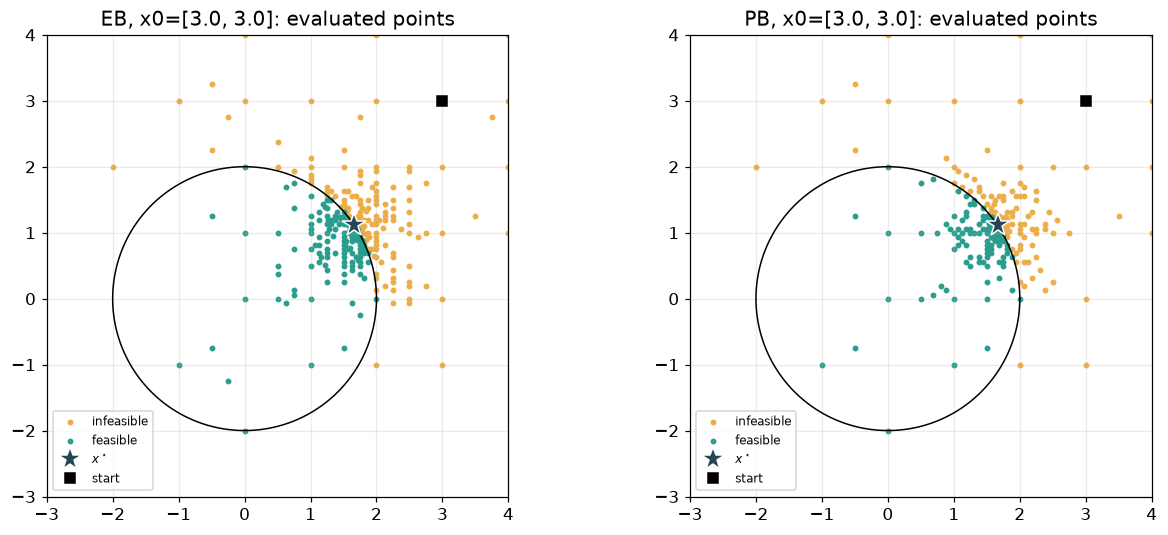

In [ ]:
path = np.array([h["x"] for h in H_cs])
fvals = np.array([h["f"] for h in H_cs])
evals = np.array([h["evals"] for h in H_cs])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].contour(X, Y, np.log10(Z + 1e-12), levels=25, cmap="Greys", linewidths=0.6)
axes[0].plot(path[:, 0], path[:, 1], "o-", ms=3, lw=1.4, color=COLORS["cs"], label="Coordinate Search")
axes[0].plot(*x_star, "*", color=COLORS["optimum"], ms=16, mec="k", label="$x^\\star$")
axes[0].set(xlabel="$x_1$", ylabel="$x_2$", title="Coordinate Search trajectory")
axes[0].legend(fontsize=8)

axes[1].semilogy(evals, np.maximum(fvals, 1e-16), "-", lw=2, color=COLORS["cs"], label="Coordinate Search")
axes[1].set(xlabel="function evaluations", ylabel="$f(x)$", title="Best objective vs budget")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

---
## 3. Coordinate Search behavior

The two plots above show:

- The CS path over objective contours.
- Best objective value versus function evaluations.

This makes the poll-and-shrink logic visible: improvement steps move the incumbent, while failed polls reduce the step size.

In [ ]:
summary = pd.DataFrame(
    {
        "final x": [tuple(np.round(x_cs, 6))],
        "f(final)": [f"{f_cs:.3e}"],
        "distance to x*": [f"{np.linalg.norm(x_cs - x_star):.3e}"],
        "evals": [int(H_cs[-1]["evals"])],
        "final step size": [f"{H_cs[-1]['delta']:.3e}"],
    },
    index=["Coordinate Search"],
)
summary

,run,fmin,hmin,xmin,blackbox calls,time [s],||xmin - x*||
0,hidden constraint (inf on crash),2.578229,1.000000e-15,"[1.67266, 1.09646]",331,0.4,0.015514
1,same constraint returned as c(x) <= 0 (PB),2.577795,1.000000e-15,"[1.6641, 1.10941]",601,1.1,0.000006


## Takeaways

1. Coordinate Search is a simple and effective derivative-free baseline.
2. Performance depends strongly on polling directions and step-size management.
3. Under a fixed budget, opportunistic polling can reduce wasted evaluations.
4. GPS and Hooke-Jeeves are covered in their dedicated notebooks.